# Sprint 4 — Arquitetura GPT e Geração de Texto

**Capítulo 4 — *Implementing a GPT model from scratch to generate text*** · RASCHKA, S. *Build a Large
Language Model (From Scratch)*, Manning. A seção sobre temperatura e top-k vem do Capítulo 5 (seção 5.3).

Este notebook percorre, passo a passo, a construção do modelo GPT da Sprint 4: os componentes do bloco
Transformer, o empilhamento dos blocos, a cabeça de saída que produz os logits e a geração
autorregressiva de texto. A lógica definitiva mora em [`src/gpt.py`](../src/gpt.py) e
[`src/geracao.py`](../src/geracao.py); aqui ela é **importada**, não reescrita — o notebook serve para
inspecionar tensores intermediários e ver o comportamento de cada etapa.

O modelo reaproveita o que foi construído antes: `EmbeddingDeEntrada` (Sprint 2,
[`src/embeddings.py`](../src/embeddings.py)) e `MultiHeadAttention` (Sprint 3,
[`src/attention.py`](../src/attention.py)).

## Roteiro

| Seção | Assunto | Referência no livro |
|---|---|---|
| 1 | Configuração do GPT-2 small e caminho dos tensores | 4.1 |
| 2 | Layer normalization | 4.2 |
| 3 | GELU × ReLU | 4.3 |
| 4 | Rede feed forward | 4.3 |
| 5 | Conexões residuais | 4.4 |
| 6 | Bloco Transformer, tensor por tensor | 4.5 |
| 7 | Modelo GPT completo | 4.6 |
| 8 | Inferência passo a passo e geração greedy | 4.7 |
| 9 | Temperatura e top-k | 5.3 |
| 10 | O que ficou para a Sprint 5 | — |

Os experimentos completos estão em [`experiments/sprint04-gpt/`](../experiments/sprint04-gpt/) e a
análise dos resultados em [`reports/sprint04-relatorio.md`](../reports/sprint04-relatorio.md).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from gpt import (
    CONFIG_GPT2_124M,
    TAMANHOS_GPT2,
    config_gpt2,
    LayerNorm,
    GELU,
    FeedForward,
    TransformerBlock,
    GPTModel,
    RedeComAtalhos,
    contar_parametros,
    parametros_por_componente,
    estimar_parametros,
    tamanho_em_mb,
)
from geracao import (
    texto_para_ids,
    ids_para_texto,
    ajustar_logits,
    selecionar_proximo_token,
    gerar,
    gerar_texto_simples,
)
from tokenizacao import TokenizadorBPE

%matplotlib inline
AZUL, LARANJA = "#2a78d6", "#eb6834"
torch.set_printoptions(precision=4, sci_mode=False)
print("torch", torch.__version__)

torch 2.13.0+cu126


---
## 1. Configuração do GPT-2 small e caminho dos tensores (seção 4.1)

O modelo inteiro é descrito por um dicionário de configuração. Os valores abaixo são os do GPT-2
"small", o menor dos quatro tamanhos lançados pela OpenAI e o usado em todo o Capítulo 4.

In [2]:
for chave, valor in CONFIG_GPT2_124M.items():
    print(f"{chave:15s} = {valor}")

vocab_size      = 50257
context_length  = 1024
emb_dim         = 768
n_heads         = 12
n_layers        = 12
drop_rate       = 0.1
qkv_bias        = False


| Chave | Significado |
|---|---|
| `vocab_size` | número de tokens do BPE do GPT-2: quantas linhas tem a tabela de embedding e quantos logits saem por posição |
| `context_length` | maior sequência que o modelo aceita: número de linhas da tabela de embedding posicional |
| `emb_dim` | dimensão `d` de todos os vetores internos: embeddings, atenção, feed forward |
| `n_heads` | cabeças de atenção em cada bloco (`head_dim = 768 / 12 = 64`) |
| `n_layers` | quantos blocos Transformer são empilhados |
| `drop_rate` | probabilidade de dropout (só age em modo de treino) |
| `qkv_bias` | se as projeções Q, K e V têm bias |

O caminho que uma sequência percorre dentro do modelo, com as formas dos tensores
(`b` = lote, `L` = número de tokens, `d` = `emb_dim`, `V` = `vocab_size`):

```
token IDs                        (b, L)        inteiros
  -> embedding de token + pos    (b, L, d)     Sprint 2
  -> dropout
  -> 12 × TransformerBlock       (b, L, d)     a forma não muda dentro dos blocos
  -> LayerNorm final             (b, L, d)
  -> cabeça de saída (Linear)    (b, L, V)     logits
```

A mesma receita, com outros valores de `emb_dim`, `n_layers` e `n_heads`, produz os quatro tamanhos
do GPT-2 (exercício 4.2). `estimar_parametros` calcula o tamanho de cada um sem instanciá-lo — o XL
não caberia na memória de muitas máquinas.

In [3]:
print(f"{'tamanho':8s} {'emb_dim':>7s} {'n_layers':>8s} {'n_heads':>7s} {'parâmetros':>15s} {'memória (MB)':>13s}")
for nome in TAMANHOS_GPT2:
    cfg = config_gpt2(nome)
    total = estimar_parametros(cfg)
    print(f"{nome:8s} {cfg['emb_dim']:7d} {cfg['n_layers']:8d} {cfg['n_heads']:7d} "
          f"{total:15,d} {tamanho_em_mb(total):13.2f}")

tamanho  emb_dim n_layers n_heads      parâmetros  memória (MB)
small        768       12      12     163,009,536        621.83
medium      1024       24      16     406,212,608       1549.58
large       1280       36      20     838,220,800       3197.56
xl          1600       48      25   1,637,792,000       6247.68


---
## 2. Layer normalization (seção 4.2)

Redes profundas sofrem quando a escala das ativações deriva de camada para camada: os gradientes
explodem ou somem e o treinamento fica instável. A **layer normalization** ajusta cada vetor de
token para média 0 e variância 1, na última dimensão.

Começamos pelo exemplo do livro: uma camada `Linear(5, 6) + ReLU` aplicada a 2 exemplos aleatórios.

In [4]:
torch.manual_seed(123)
batch_example = torch.randn(2, 5)          # 2 exemplos, 5 características
camada = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = camada(batch_example)
print("saída da camada (2, 6):")
print(out)
print("\nmédia por linha    :", out.mean(dim=-1).detach())
print("variância por linha:", out.var(dim=-1).detach())
print("\nlivro: médias [0.1324, 0.2170], variâncias [0.0231, 0.0398]")

saída da camada (2, 6):
tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)

média por linha    : tensor([0.1324, 0.2170])
variância por linha: tensor([0.0231, 0.0398])

livro: médias [0.1324, 0.2170], variâncias [0.0231, 0.0398]


### Normalizando à mão

Subtrair a média e dividir pelo desvio-padrão de cada linha:

In [5]:
media = out.mean(dim=-1, keepdim=True)
variancia = out.var(dim=-1, keepdim=True, unbiased=False)
out_norm = (out - media) / torch.sqrt(variancia)
print(out_norm.detach())
print("\nmédia    :", out_norm.mean(dim=-1).detach())
print("variância:", out_norm.var(dim=-1, unbiased=False).detach())

tensor([[ 0.6746,  1.5474, -0.9551,  0.6433, -0.9551, -0.9551],
        [-0.0207,  0.1228, -1.1915,  1.6621,  0.6186, -1.1915]])

média    : tensor([-0.0000, -0.0000])
variância: tensor([1., 1.])


### A classe `LayerNorm`

A classe faz a mesma conta, com duas adições:

- `eps = 1e-5` somado à variância, para nunca dividir por zero;
- dois parâmetros treináveis, `scale` (começa em 1) e `shift` (começa em 0), que deixam o modelo
  reescalar e deslocar o resultado se isso ajudar. Na inicialização, a camada é uma normalização pura.

Como no livro, aplicamos a camada diretamente ao `batch_example` de 5 dimensões.

In [6]:
ln = LayerNorm(emb_dim=5)
out_ln = ln(batch_example)
print("média    :", out_ln.mean(dim=-1).detach())
print("variância:", out_ln.var(dim=-1, unbiased=False).detach())
print("parâmetros: scale", tuple(ln.scale.shape), "+ shift", tuple(ln.shift.shape),
      "=", contar_parametros(ln))

referencia = nn.LayerNorm(5, eps=1e-5)
print("\nigual a torch.nn.LayerNorm:", torch.allclose(out_ln, referencia(batch_example), atol=1e-6))

média    : tensor([-0.0000,  0.0000])
variância: tensor([1.0000, 1.0000])
parâmetros: scale (5,) + shift (5,) = 10

igual a torch.nn.LayerNorm: True


**Por que normalizar por token, e não por lote?** A *batch normalization*, comum em visão
computacional, normaliza cada característica usando todos os exemplos do lote. A layer normalization
usa apenas as `d` componentes de um único token. Isso a torna independente do tamanho do lote — o que
importa na geração, em que o lote tem um único exemplo, e em treinamentos distribuídos com lotes
pequenos por dispositivo.

---
## 3. GELU × ReLU (seção 4.3)

A rede feed forward de cada bloco usa a ativação **GELU** (*Gaussian Error Linear Unit*), na
aproximação usada no GPT-2:

$$\mathrm{GELU}(x) \approx 0{,}5\,x\left(1 + \tanh\!\left[\sqrt{2/\pi}\,\left(x + 0{,}044715\,x^3\right)\right]\right)$$

Comparamos com a ReLU, `max(0, x)`, em alguns pontos:

In [7]:
pontos = torch.tensor([-3.0, -1.0, -0.5, -0.1, 0.0, 0.1, 0.5, 1.0, 3.0])
gelu, relu = GELU(), nn.ReLU()
print(f"{'x':>6s} {'GELU(x)':>9s} {'ReLU(x)':>9s}")
for x, g, r in zip(pontos, gelu(pontos), relu(pontos)):
    print(f"{x.item():6.2f} {g.item():9.4f} {r.item():9.4f}")

     x   GELU(x)   ReLU(x)
 -3.00   -0.0036    0.0000
 -1.00   -0.1588    0.0000
 -0.50   -0.1543    0.0000
 -0.10   -0.0460    0.0000
  0.00    0.0000    0.0000
  0.10    0.0540    0.1000
  0.50    0.3457    0.5000
  1.00    0.8412    1.0000
  3.00    2.9964    3.0000


As curvas e suas derivadas, calculadas com *autograd*:

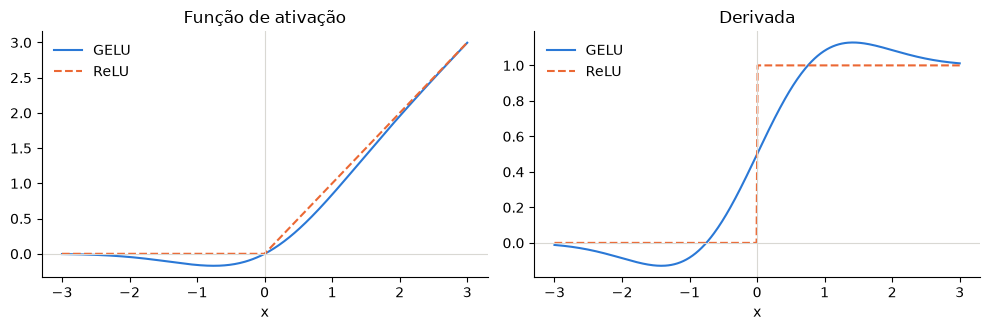

In [8]:
x = torch.linspace(-3, 3, 400, requires_grad=True)
y_gelu, y_relu = gelu(x), relu(x)
(d_gelu,) = torch.autograd.grad(y_gelu.sum(), x)
(d_relu,) = torch.autograd.grad(y_relu.sum(), x)
x_np = x.detach().numpy()

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, (titulo, gy, ry) in zip(
    eixos,
    [("Função de ativação", y_gelu, y_relu), ("Derivada", d_gelu, d_relu)],
):
    ax.plot(x_np, gy.detach().numpy(), color=AZUL, label="GELU")
    ax.plot(x_np, ry.detach().numpy(), color=LARANJA, linestyle="--", label="ReLU")
    ax.axhline(0, color="#d9d8d3", linewidth=0.8)
    ax.axvline(0, color="#d9d8d3", linewidth=0.8)
    ax.set_title(titulo)
    ax.set_xlabel("x")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
fig.tight_layout()
plt.show()

Duas diferenças contam para o treinamento:

- **para `x < 0` a derivada da ReLU é exatamente zero.** Um neurônio cuja entrada fica negativa para
  todos os exemplos para de receber gradiente e não volta a aprender. A GELU mantém uma derivada
  pequena, mas não nula, nessa região;
- **a GELU é suave em `x = 0`**, enquanto a ReLU tem um "bico" (a derivada salta de 0 para 1). A
  suavidade torna a otimização mais bem-comportada.

A GELU ainda admite saídas levemente negativas (o mínimo fica perto de −0,17), o que a ReLU não
permite.

---
## 4. Rede feed forward (seção 4.3)

Cada bloco tem uma pequena rede de duas camadas lineares com GELU no meio. Ela é aplicada a **cada
token separadamente** — os tokens não trocam informação aqui; isso é papel da atenção. A rede expande
o vetor para `4 · d` dimensões e depois o comprime de volta.

In [9]:
ff = FeedForward(CONFIG_GPT2_124M)
print(ff)

torch.manual_seed(123)
x = torch.rand(2, 3, 768)              # 2 sequências, 3 tokens, 768 dimensões
expandido = ff.layers[0](x)
ativado = ff.layers[1](expandido)
comprimido = ff.layers[2](ativado)

print("\nentrada            :", tuple(x.shape))
print("após Linear 768->3072:", tuple(expandido.shape))
print("após GELU          :", tuple(ativado.shape))
print("após Linear 3072->768:", tuple(comprimido.shape))
print("igual a ff(x)      :", torch.allclose(comprimido, ff(x)))

FeedForward(
  (layers): Sequential(
    (0): Linear(in_features=768, out_features=3072, bias=True)
    (1): GELU()
    (2): Linear(in_features=3072, out_features=768, bias=True)
  )
)

entrada            : (2, 3, 768)
após Linear 768->3072: (2, 3, 3072)
após GELU          : (2, 3, 3072)
após Linear 3072->768: (2, 3, 768)
igual a ff(x)      : True


In [10]:
w1, b1 = ff.layers[0].weight, ff.layers[0].bias
w2, b2 = ff.layers[2].weight, ff.layers[2].bias
print(f"Linear 1: pesos {tuple(w1.shape)} + bias {tuple(b1.shape)} = {w1.numel() + b1.numel():,}")
print(f"Linear 2: pesos {tuple(w2.shape)} + bias {tuple(b2.shape)} = {w2.numel() + b2.numel():,}")
print(f"total da feed forward: {contar_parametros(ff):,}   (livro, exercício 4.1: 4,722,432)")

Linear 1: pesos (3072, 768) + bias (3072,) = 2,362,368
Linear 2: pesos (768, 3072) + bias (768,) = 2,360,064
total da feed forward: 4,722,432   (livro, exercício 4.1: 4,722,432)


A expansão para 3.072 dimensões dá à rede um espaço maior para combinar as características que a
atenção reuniu antes de comprimi-las de volta. O preço aparece na contagem: com 4,7 milhões de
parâmetros por bloco, a feed forward tem o **dobro** dos parâmetros da atenção do mesmo bloco
(2,36 milhões, seção 6).

---
## 5. Conexões residuais (seção 4.4)

Em uma rede profunda, o gradiente que chega às primeiras camadas é o produto das derivadas de todas as
camadas seguintes. Se esses fatores forem menores que 1, o produto encolhe camada a camada: é o
**desaparecimento do gradiente**, e as primeiras camadas praticamente deixam de aprender.

A **conexão residual** (*shortcut*) soma a entrada de uma camada à sua saída: `x = x + camada(x)`.
A derivada dessa soma em relação a `x` tem um termo constante igual a 1, que oferece ao gradiente um
caminho direto de volta.

O livro ilustra o efeito com uma rede de 5 camadas `Linear + GELU` (`RedeComAtalhos`), comparando a
média do gradiente absoluto de cada camada com e sem atalhos.

In [11]:
def gradientes_por_camada(usar_atalhos):
    torch.manual_seed(123)
    rede = RedeComAtalhos([3, 3, 3, 3, 3, 1], usar_atalhos)
    saida = rede(torch.tensor([[1.0, 0.0, -1.0]]))
    nn.MSELoss()(saida, torch.tensor([[0.0]])).backward()
    return [p.grad.abs().mean().item() for nome, p in rede.named_parameters() if "weight" in nome]

sem = gradientes_por_camada(False)
com = gradientes_por_camada(True)
print(f"{'camada':>6s} {'sem atalhos':>14s} {'com atalhos':>14s} {'razão':>9s}")
for i, (s, c) in enumerate(zip(sem, com)):
    print(f"{i:6d} {s:14.8f} {c:14.8f} {c / s:9.0f}x")

camada    sem atalhos    com atalhos     razão
     0     0.00020174     0.22169791      1099x
     1     0.00012011     0.20694102      1723x
     2     0.00071520     0.32896996       460x
     3     0.00139887     0.26657322       191x
     4     0.00504965     1.32585418       263x


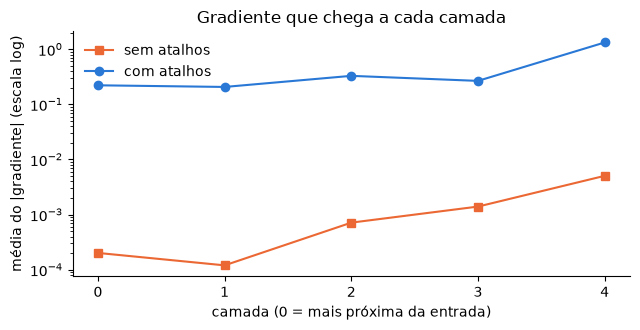

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
camadas = range(len(sem))
ax.plot(camadas, sem, color=LARANJA, marker="s", label="sem atalhos")
ax.plot(camadas, com, color=AZUL, marker="o", label="com atalhos")
ax.set_yscale("log")
ax.set_xticks(list(camadas))
ax.set_xlabel("camada (0 = mais próxima da entrada)")
ax.set_ylabel("média do |gradiente| (escala log)")
ax.set_title("Gradiente que chega a cada camada")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

Sem atalhos, o gradiente da primeira camada é cerca de **25 vezes menor** que o da última; com
atalhos, as cinco camadas recebem gradientes da mesma ordem de grandeza — e a primeira recebe mais de
**mil vezes** mais gradiente do que receberia sem eles. Os valores conferem com os do livro.

No GPT, cada bloco tem duas conexões residuais, uma em volta da atenção e outra em volta da feed
forward. Com 12 blocos, são 24 caminhos diretos da saída até a entrada.

---
## 6. Bloco Transformer, tensor por tensor (seção 4.5)

O bloco reúne tudo o que vimos até aqui, no padrão *pre-LayerNorm* (a normalização vem **antes** de
cada subcamada):

```
x -> LayerNorm -> MultiHeadAttention -> Dropout -> (+ x)     # mistura informação entre os tokens
  -> LayerNorm -> FeedForward        -> Dropout -> (+ x)     # processa cada token
```

Para ver a forma de cada tensor intermediário, percorremos o bloco à mão, chamando seus submódulos na
mesma ordem do `forward`. O bloco fica em modo `eval()`, para que o dropout não interfira.

In [13]:
torch.manual_seed(123)
x = torch.rand(2, 4, 768)                         # 2 sequências, 4 tokens, 768 dimensões
bloco = TransformerBlock(CONFIG_GPT2_124M).eval()
print(bloco)

TransformerBlock(
  (att): MultiHeadAttention(
    (W_query): Linear(in_features=768, out_features=768, bias=False)
    (W_key): Linear(in_features=768, out_features=768, bias=False)
    (W_value): Linear(in_features=768, out_features=768, bias=False)
    (out_proj): Linear(in_features=768, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (ff): FeedForward(
    (layers): Sequential(
      (0): Linear(in_features=768, out_features=3072, bias=True)
      (1): GELU()
      (2): Linear(in_features=3072, out_features=768, bias=True)
    )
  )
  (norm1): LayerNorm()
  (norm2): LayerNorm()
  (drop_shortcut): Dropout(p=0.1, inplace=False)
)


In [14]:
formas = []
with torch.no_grad():
    formas.append(("entrada x", x))

    atalho = x
    h = bloco.norm1(x);                          formas.append(("norm1", h))
    h, pesos = bloco.att(h, return_attn_weights=True)
    formas.append(("pesos de atenção (b, h, L, L)", pesos))
    formas.append(("saída da atenção", h))
    h = bloco.drop_shortcut(h)
    h = h + atalho;                              formas.append(("+ atalho (residual 1)", h))

    atalho = h
    h = bloco.norm2(h);                          formas.append(("norm2", h))
    h = bloco.ff.layers[0](h);                   formas.append(("feed forward: expansão", h))
    h = bloco.ff.layers[1](h);                   formas.append(("feed forward: GELU", h))
    h = bloco.ff.layers[2](h);                   formas.append(("feed forward: compressão", h))
    h = bloco.drop_shortcut(h)
    saida = h + atalho;                          formas.append(("+ atalho (residual 2)", saida))

for nome, t in formas:
    print(f"{nome:32s} {str(tuple(t.shape)):>18s}")

with torch.no_grad():
    print("\nigual a bloco(x):", torch.allclose(saida, bloco(x), atol=1e-6))

entrada x                               (2, 4, 768)
norm1                                   (2, 4, 768)
pesos de atenção (b, h, L, L)         (2, 12, 4, 4)
saída da atenção                        (2, 4, 768)
+ atalho (residual 1)                   (2, 4, 768)
norm2                                   (2, 4, 768)
feed forward: expansão                 (2, 4, 3072)
feed forward: GELU                     (2, 4, 3072)
feed forward: compressão                (2, 4, 768)
+ atalho (residual 2)                   (2, 4, 768)

igual a bloco(x): True


Pontos a observar:

- a saída tem **a mesma forma da entrada**, `(2, 4, 768)`. É isso que permite empilhar blocos: a saída
  de um é a entrada do seguinte;
- dentro da atenção aparecem `12` matrizes `4 × 4` por sequência — uma por cabeça —, cada uma
  triangular por causa da máscara causal;
- a feed forward passa por `(2, 4, 3072)`, a maior forma intermediária do bloco.

A matriz de atenção da primeira cabeça, para a primeira sequência (pesos aleatórios — o modelo não foi
treinado):

In [15]:
print(pesos[0, 0])
print("\ncada linha soma 1:", torch.allclose(pesos[0, 0].sum(-1), torch.ones(4)))

tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.6126, 0.3874, 0.0000, 0.0000],
        [0.4218, 0.2585, 0.3198, 0.0000],
        [0.1469, 0.3077, 0.2390, 0.3065]])

cada linha soma 1: True


In [16]:
print(f"parâmetros da atenção     : {contar_parametros(bloco.att):,}   (livro: 2,360,064)")
print(f"parâmetros da feed forward: {contar_parametros(bloco.ff):,}   (livro: 4,722,432)")
print(f"parâmetros das 2 LayerNorm: {contar_parametros(bloco.norm1) + contar_parametros(bloco.norm2):,}")
print(f"total do bloco            : {contar_parametros(bloco):,}")

parâmetros da atenção     : 2,360,064   (livro: 2,360,064)
parâmetros da feed forward: 4,722,432   (livro: 4,722,432)
parâmetros das 2 LayerNorm: 3,072
total do bloco            : 7,085,568


---
## 7. Modelo GPT completo (seção 4.6)

O `GPTModel` empilha 12 blocos entre a camada de entrada e a cabeça de saída:

| Componente | Classe | Forma da saída |
|---|---|---|
| `embedding` | `EmbeddingDeEntrada` (Sprint 2): token + posição | `(b, L, 768)` |
| `drop_emb` | `nn.Dropout` | `(b, L, 768)` |
| `trf_blocks` | 12 × `TransformerBlock` | `(b, L, 768)` |
| `final_norm` | `LayerNorm` | `(b, L, 768)` |
| `out_head` | `nn.Linear(768, 50257, bias=False)` — a *language model head* | `(b, L, 50257)` |

Usamos o mesmo lote do livro: duas frases de 4 tokens.

In [17]:
bpe = TokenizadorBPE()
lote = torch.tensor([bpe.encode("Every effort moves you"), bpe.encode("Every day holds a")])
print("lote de token IDs (2, 4):")
print(lote)

lote de token IDs (2, 4):
tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


In [18]:
torch.manual_seed(123)
modelo = GPTModel(CONFIG_GPT2_124M)
logits = modelo(lote)              # em modo de treino, como no livro
print("forma dos logits:", tuple(logits.shape))
print(logits)

forma dos logits: (2, 4, 50257)
tensor([[[ 0.3613,  0.4222, -0.0711,  ...,  0.3483,  0.4661, -0.2838],
         [-0.1792, -0.5660, -0.9485,  ...,  0.0477,  0.5181, -0.3168],
         [ 0.7120,  0.0332,  0.1085,  ...,  0.1018, -0.4327, -0.2553],
         [-1.0076,  0.3418, -0.1190,  ...,  0.7195,  0.4023,  0.0532]],

        [[-0.2564,  0.0900,  0.0335,  ...,  0.2659,  0.4454, -0.6806],
         [ 0.1230,  0.3653, -0.2074,  ...,  0.7705,  0.2710,  0.2246],
         [ 1.0558,  1.0318, -0.2800,  ...,  0.6936,  0.3205, -0.3178],
         [-0.1565,  0.3926,  0.3288,  ...,  1.2630, -0.1858,  0.0388]]],
       grad_fn=<UnsafeViewBackward0>)


Para cada uma das `2 × 4` posições, o modelo produz **50.257 números** — um para cada token do
vocabulário. Esses números são os **logits**: pontuações, ainda não probabilidades. Os valores
conferem com os do livro (`0.3613, 0.4222, -0.0711, …` na primeira posição).

### Quantos parâmetros?

In [19]:
total = contar_parametros(modelo)
sem_cabeca = contar_parametros(modelo, sem_cabeca=True)
print(f"parâmetros totais                    : {total:,}   (livro: 163,009,536)")
print(f"descontando a cabeça (weight tying)  : {sem_cabeca:,}   (livro: 124,412,160)")
print(f"memória em float32                   : {tamanho_em_mb(total):.2f} MB   (livro: 621.83 MB)")

parâmetros totais                    : 163,009,536   (livro: 163,009,536)
descontando a cabeça (weight tying)  : 124,412,160   (livro: 124,412,160)
memória em float32                   : 621.83 MB   (livro: 621.83 MB)


In [20]:
partes = parametros_por_componente(modelo)
print(f"{'componente':32s} {'parâmetros':>13s} {'%':>6s}")
for nome, n in partes.items():
    print(f"{nome:32s} {n:13,d} {100 * n / total:6.1f}")
print(f"{'total':32s} {total:13,d}")

componente                          parâmetros      %
embedding de token                  38,597,376   23.7
embedding posicional                   786,432    0.5
atenção (todos os blocos)           28,320,768   17.4
feed forward (todos os blocos)      56,669,184   34.8
LayerNorm (blocos + final)              38,400    0.0
cabeça de saída                     38,597,376   23.7
total                              163,009,536


Duas observações:

- **o vocabulário custa caro.** A tabela de embedding de tokens e a cabeça de saída têm, cada uma,
  `50.257 × 768 = 38,6 milhões` de parâmetros. Juntas são quase metade do modelo;
- **por que "124M" e não 163M?** O GPT-2 original usa a **mesma matriz** para a tabela de embedding e
  para a cabeça de saída (*weight tying*), já que as duas têm forma `(50.257, 768)`. O livro mantém as
  duas separadas, que tende a treinar melhor; a configuração `compartilhar_pesos=True` ativa o
  compartilhamento:

In [21]:
torch.manual_seed(123)
amarrado = GPTModel(dict(CONFIG_GPT2_124M, compartilhar_pesos=True))
print(f"parâmetros com compartilhamento: {contar_parametros(amarrado):,}")
print("cabeça e embedding são a mesma matriz:",
      amarrado.out_head.weight is amarrado.embedding.token_emb.weight)
del amarrado

parâmetros com compartilhamento: 124,412,160
cabeça e embedding são a mesma matriz: True


---
## 8. Inferência passo a passo e geração greedy (seção 4.7)

O modelo só sabe fazer uma coisa: dado um texto, dar uma pontuação para cada token do vocabulário ser o
próximo. Gerar texto é repetir essa operação em um laço:

1. passar o contexto pelo modelo → logits `(1, L, 50257)`;
2. pegar só os logits da **última** posição → `(1, 50257)`: é ela que prevê o token seguinte ao texto
   inteiro;
3. converter em probabilidades com softmax e escolher um token;
4. anexar o token ao contexto e voltar ao passo 1.

Antes de gerar, o modelo vai para o modo `eval()`: o dropout é desligado e a saída passa a ser
determinística.

### Um único passo, à mão

In [22]:
modelo.eval()
contexto = texto_para_ids("Hello, I am")
print("contexto:", contexto.tolist(), "forma", tuple(contexto.shape))

with torch.no_grad():
    logits = modelo(contexto)
print("logits de todas as posições:", tuple(logits.shape))

ultimo = logits[:, -1, :]
print("logits da última posição   :", tuple(ultimo.shape))

probabilidades = torch.softmax(ultimo, dim=-1)
print("soma das probabilidades    :", probabilidades.sum().item())

contexto: [[15496, 11, 314, 716]] forma (1, 4)
logits de todas as posições: (1, 4, 50257)
logits da última posição   : (1, 50257)
soma das probabilidades    : 0.9999997615814209


In [23]:
top = torch.topk(probabilidades, k=5, dim=-1)
print("os 5 tokens mais prováveis:")
for p, i in zip(top.values[0], top.indices[0]):
    print(f"  {i.item():6d}  {bpe.decode([i.item()])!r:16s} logit {ultimo[0, i].item():7.3f}  prob {p.item():.6f}")

proximo = torch.argmax(ultimo, dim=-1, keepdim=True)
print("\nargmax dos logits:", proximo.item(), "| argmax das probabilidades:",
      torch.argmax(probabilidades).item())
contexto = torch.cat((contexto, proximo), dim=1)
print("novo contexto:", contexto.tolist(), "->", repr(ids_para_texto(contexto)))

os 5 tokens mais prováveis:
   27018  ' Feature'       logit   2.497  prob 0.000205
   40179  '677'            logit   2.183  prob 0.000150
   42473  'TRUMP'          logit   2.138  prob 0.000143
   14888  ' participated'  logit   2.137  prob 0.000143
   22592  'retch'          logit   2.135  prob 0.000143

argmax dos logits: 27018 | argmax das probabilidades: 27018
novo contexto: [[15496, 11, 314, 716, 27018]] -> 'Hello, I am Feature'


Três coisas aparecem neste passo:

- **logits → probabilidades.** O softmax transforma as 50.257 pontuações em uma distribuição positiva
  que soma 1, preservando a ordem;
- **escolha greedy.** Como o softmax preserva a ordem, o token de maior logit é também o de maior
  probabilidade: para a escolha *greedy* o softmax nem é necessário;
- **probabilidades quase uniformes.** O token escolhido tem probabilidade de cerca de `0,0002` —
  dez vezes o valor de uma distribuição uniforme (`1/50.257 ≈ 0,00002`), mas ainda ínfima, e os cinco
  primeiros estão praticamente empatados. É o que se espera de um modelo com pesos aleatórios: ele
  ainda não tem preferência real por nenhum token.

### O laço completo

`gerar_texto_simples` repete o passo acima. Com a semente 123 do livro, a geração de 6 tokens a partir
de *"Hello, I am"* reproduz a saída publicada:

In [24]:
inicio = texto_para_ids("Hello, I am")
saida = gerar_texto_simples(modelo, inicio, max_novos_tokens=6,
                            tamanho_contexto=CONFIG_GPT2_124M["context_length"])
print("token IDs:", saida.tolist())
print("tamanho  :", saida.shape[1], "(4 do contexto + 6 gerados)")
print("texto    :", repr(ids_para_texto(saida)))

token IDs: [[15496, 11, 314, 716, 27018, 24086, 47843, 30961, 42348, 7267]]
tamanho  : 10 (4 do contexto + 6 gerados)
texto    : 'Hello, I am Featureiman Byeswickattribute argue'


O texto é desconexo porque o modelo **não foi treinado**: os pesos ainda são os da inicialização
aleatória. A mecânica da geração, porém, está completa — o mesmo laço, com os pesos aprendidos na
Sprint 5 (ou com os pesos públicos do GPT-2), produz texto coerente.

**Janela de contexto.** Antes de cada passo, `gerar` corta o contexto para os últimos
`tamanho_contexto` tokens (`ids[:, -tamanho_contexto:]`), porque o modelo não aceita sequências
maiores que `context_length`. Tokens mais antigos que isso deixam de influenciar a previsão.

---
## 9. Temperatura e top-k (seção 5.3)

A escolha *greedy* é determinística: o mesmo contexto produz sempre o mesmo texto, e modelos treinados
tendem a cair em repetições. As alternativas sorteiam o próximo token a partir das probabilidades,
controladas por dois parâmetros:

- **temperatura `T`** — divide os logits antes do softmax. `T < 1` acentua as diferenças (a
  distribuição se concentra no favorito); `T > 1` as suaviza (a distribuição se espalha);
- **top-k** — antes do sorteio, mantém só os `k` tokens de maior logit; os demais recebem `-inf` e
  probabilidade zero.

Para enxergar o efeito, o livro usa um vocabulário de brinquedo com 9 palavras e logits fixos para o
próximo token depois de *"every effort moves you"*:

In [25]:
vocab = ["closer", "every", "effort", "forward", "inches", "moves", "pizza", "toward", "you"]
logits_ex = torch.tensor([[4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]])

print("greedy:", vocab[selecionar_proximo_token(logits_ex).item()])

temperaturas = [0.1, 1.0, 5.0]
distribuicoes = {t: torch.softmax(ajustar_logits(logits_ex, t), dim=-1)[0] for t in temperaturas}
for t, p in distribuicoes.items():
    print(f"\nT = {t}:")
    print("  " + "  ".join(f"{w}={v:.3f}" for w, v in zip(vocab, p.tolist())))

greedy: forward

T = 0.1:
  closer=0.000  every=0.000  effort=0.000  forward=0.991  inches=0.000  moves=0.000  pizza=0.000  toward=0.009  you=0.000

T = 1.0:
  closer=0.061  every=0.002  effort=0.000  forward=0.572  inches=0.003  moves=0.000  pizza=0.000  toward=0.358  you=0.004

T = 5.0:
  closer=0.155  every=0.075  effort=0.043  forward=0.242  inches=0.087  moves=0.045  pizza=0.043  toward=0.220  you=0.090


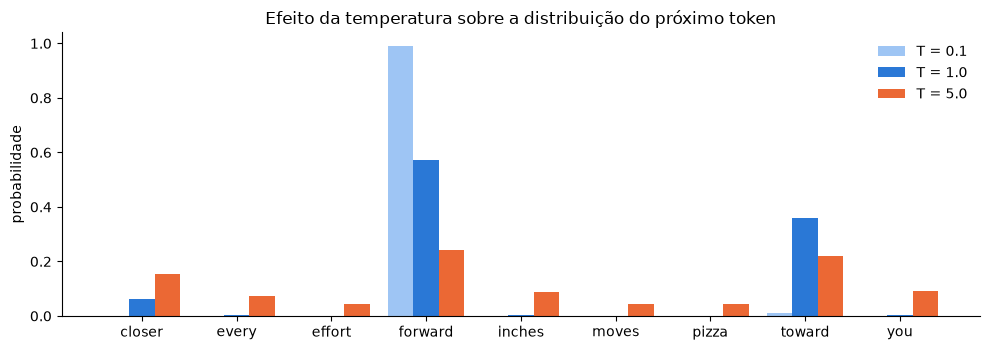

In [26]:
fig, ax = plt.subplots(figsize=(10, 3.6))
largura = 0.27
cores = ["#9ec5f4", AZUL, LARANJA]
for i, (t, p) in enumerate(distribuicoes.items()):
    ax.bar([j + (i - 1) * largura for j in range(len(vocab))], p.numpy(),
           width=largura, color=cores[i], label=f"T = {t}")
ax.set_xticks(range(len(vocab)), vocab)
ax.set_ylabel("probabilidade")
ax.set_title("Efeito da temperatura sobre a distribuição do próximo token")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

Sorteando 1.000 vezes com `T = 1` (semente 123), a frequência de cada palavra acompanha sua
probabilidade — e reproduz a contagem do livro:

In [27]:
def contar_sorteios(temperatura, top_k=None, n=1000, semente=123):
    torch.manual_seed(semente)
    ids = [selecionar_proximo_token(logits_ex, temperatura=temperatura, top_k=top_k).item()
           for _ in range(n)]
    return torch.bincount(torch.tensor(ids), minlength=len(vocab)).tolist()

for t in temperaturas:
    contagem = contar_sorteios(t)
    print(f"T = {t}: " + ", ".join(f"{c} x {w}" for w, c in zip(vocab, contagem) if c))
print("\nlivro (T = 1): 73 x closer, 582 x forward, 2 x inches, 343 x toward")

T = 0.1: 985 x forward, 15 x toward
T = 1.0: 73 x closer, 582 x forward, 2 x inches, 343 x toward
T = 5.0: 165 x closer, 75 x every, 42 x effort, 239 x forward, 71 x inches, 46 x moves, 32 x pizza, 227 x toward, 103 x you

livro (T = 1): 73 x closer, 582 x forward, 2 x inches, 343 x toward


Com `T = 5`, palavras sem relação com o contexto, como *pizza*, passam a ser escolhidas de vez em
quando. O **top-k** evita isso: com `k = 3`, só *closer*, *forward* e *toward* sobrevivem.

In [28]:
filtrados = ajustar_logits(logits_ex, temperatura=1.0, top_k=3)
print("logits após top-k = 3:", filtrados)
print("probabilidades       :", torch.softmax(filtrados, dim=-1))
print("livro                : [0.0615, 0, 0, 0.5775, 0, 0, 0, 0.3610, 0]")

contagem = contar_sorteios(5.0, top_k=3)
print("\nT = 5 com top-k = 3: " + ", ".join(f"{c} x {w}" for w, c in zip(vocab, contagem) if c))

logits após top-k = 3: tensor([[4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf]])
probabilidades       : tensor([[0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000]])
livro                : [0.0615, 0, 0, 0.5775, 0, 0, 0, 0.3610, 0]



T = 5 com top-k = 3: 258 x closer, 385 x forward, 357 x toward


### As mesmas estratégias no GPT

Agora com o modelo de 124M parâmetros. Lembrete: o modelo **não foi treinado**, então nenhuma das
estratégias produz texto com sentido — o objetivo aqui é ver a mecânica: o *greedy* é sempre igual a si
mesmo, enquanto os sorteios mudam com a semente.

In [29]:
inicio = texto_para_ids("Every effort moves you")
estrategias = [
    ("greedy", dict(temperatura=0.0)),
    ("T = 1", dict(temperatura=1.0)),
    ("T = 1, top-k = 50", dict(temperatura=1.0, top_k=50)),
    ("T = 0.5, top-k = 50", dict(temperatura=0.5, top_k=50)),
]
for nome, params in estrategias:
    for semente in (123, 456):
        torch.manual_seed(semente)
        saida = gerar(modelo, inicio, max_novos_tokens=8, tamanho_contexto=1024, **params)
        print(f"{nome:20s} semente {semente}: {ids_para_texto(saida)!r}")

greedy               semente 123: 'Every effort moves you Aeiman Byeswickattributeometer inspector Normandy'


greedy               semente 456: 'Every effort moves you Aeiman Byeswickattributeometer inspector Normandy'


T = 1                semente 123: 'Every effort moves you Jolly rendering GroundTaskfinalTweetntonbanks'


T = 1                semente 456: 'Every effort moves you hacking anomalSure Ax 107 perpetually years Ezek'


T = 1, top-k = 50    semente 123: 'Every effort moves you JC Turnbullitional cred blocigarettes earners THEY'


T = 1, top-k = 50    semente 456: 'Every effort moves you Crab Dough Likes .. reminisidelHAEL Ion'


T = 0.5, top-k = 50  semente 123: 'Every effort moves you JC Turnbull toollimit activityUniversityCertainhaired'


T = 0.5, top-k = 50  semente 456: 'Every effort moves you Crab Dough Likes .. scientists necorship normalized'


Com pesos aleatórios, os logits do modelo são muito parecidos entre si, então a distribuição de
probabilidade é quase uniforme sobre os 50.257 tokens. Por isso o sorteio com `T = 1` escolhe tokens
praticamente ao acaso, e o top-k é o que mais muda o resultado: restringe o sorteio aos 50 tokens de
maior logit. Depois do treinamento, os logits passam a ter diferenças grandes, e temperatura e top-k
tornam-se ajustes finos entre previsibilidade e variedade.

---
## 10. O que ficou para a Sprint 5

O modelo está completo: recebe token IDs, produz logits e gera texto token a token. Falta o que dá
sentido aos pesos:

- **função de perda** — comparar os logits de cada posição com o token que de fato vem a seguir (os
  alvos que o `GPTDatasetV1` da Sprint 2 já produz), usando entropia cruzada;
- **laço de treinamento** — otimizador, retropropagação e atualização dos pesos ao longo das épocas;
- **avaliação** — perda de treino e de validação, e a qualidade do texto gerado antes e depois do
  treinamento.

| Componente | Onde está |
|---|---|
| `LayerNorm`, `GELU`, `FeedForward`, `TransformerBlock`, `GPTModel` | [`src/gpt.py`](../src/gpt.py) |
| Inferência, temperatura, top-k e geração | [`src/geracao.py`](../src/geracao.py) |
| Validação contra o livro (38 verificações) | [`src/validar_gpt.py`](../src/validar_gpt.py) |

```bash
python src/validar_gpt.py
```